# 01b-audit-followup: questions the first audit raised

The first audit showed the 786 scans are not one homogeneous dataset. Before
Phase 1 we need five answers, all of which change how the detector is built:

1. **Scaling:** which scans are z-scored, and does that follow scan length?
2. **Independence:** which scans are duplicates or near-duplicates?
3. **Cleaning:** the supplied FNC is not the correlation of the supplied
   time-courses, so what cleaning reproduces it? That also hints at TR.
4. **Stationarity:** is variance lower at the start of a scan? A monitoring
   detector calibrates on those volumes, so this matters most.
5. **Bursts and redundancy:** how common are artifact bursts, and which of the
   105 ICNs are near-copies of each other?

All scans are one pool here and diagnosis labels are not read.

**To run:** attach the data, then Save & Run All. Everything needed is printed
in the notebook, so the saved notebook alone is enough to send back.

In [1]:
import hashlib
import json
import logging
import os
import shutil
import subprocess
import sys
import time
import traceback
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.cluster.hierarchy as sch
import scipy.signal
from scipy.sparse.csgraph import connected_components
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from tqdm.auto import tqdm

SEED = 20261031
rng = np.random.default_rng(SEED)

INPUT_ROOT = Path(os.environ.get("DFCPD_INPUT", "/kaggle/input"))
WORK_ROOT = Path(os.environ.get("DFCPD_WORKING", "/kaggle/working"))
OUT = WORK_ROOT / "01b-followup"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

P = 105
UPPER = np.triu_indices(P, 1)
M = 60
MIN_T_FOR_M = 180
N_RECON_SCANS = 30
CUTOFFS = (None, .10, .15, .20, .25, .30, .35, .40, .45)
N_SURROGATES = 5
N_BOOT = 2000

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(message)s", stream=sys.stdout, force=True)
log = logging.getLogger("followup")
log.info("seed=%d input=%s output=%s", SEED, INPUT_ROOT, OUT)
(OUT / "pip_freeze.txt").write_text(
    subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True).stdout
)

SUMMARY = {"seed": SEED, "sections_failed": []}


def step(fn):
    """Run a section now, and keep going if it fails."""
    log.info("START %s", fn.__name__)
    t0 = time.time()
    try:
        fn()
        log.info("DONE  %s (%.1fs)", fn.__name__, time.time() - t0)
    except Exception:
        SUMMARY["sections_failed"].append(fn.__name__)
        with open(OUT / "errors.txt", "a") as f:
            f.write(f"--- {fn.__name__} ---\n{traceback.format_exc()}\n")
        log.exception("FAILED %s", fn.__name__)
    return fn

2026-10-30 23:51:55,533 seed=20261031 input=/kaggle/input output=/kaggle/working/01b-followup


In [2]:
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#2b2b29", "#6f6e69", "#e4e2dc"
DIV_FNC = LinearSegmentedColormap.from_list("div_fnc", ["#184f95", "#6da7ec", "#f0efec", "#ec8a8a", "#b52f2f"])
LINE_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

plt.rcParams.update({
    "figure.dpi": 130, "savefig.bbox": "tight", "font.size": 9, "axes.titlesize": 10,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "lines.linewidth": 2, "legend.frameon": False,
})


def save_fig(fig, name):
    fig.savefig(FIG / f"{name}.png")
    plt.show()
    plt.close(fig)


def zscore(x):
    return (x - x.mean(0)) / x.std(0)


def phase_randomise(x, generator):
    """Surrogate with shared random phases, which keeps auto- and cross-spectra."""
    spectrum = np.fft.rfft(x - x.mean(0), axis=0)
    phases = np.exp(2j * np.pi * generator.random(spectrum.shape[0]))
    phases[0] = 1
    return np.fft.irfft(spectrum * phases[:, None], n=len(x), axis=0)


def frame_energy(x):
    """Mean squared z per volume, about 1 everywhere for a stationary scan."""
    return (zscore(x) ** 2).mean(1)


def square(vector):
    m = np.eye(P)
    m[UPPER] = vector
    m[(UPPER[1], UPPER[0])] = vector
    return m


TC, FNC, FOLDER = {}, {}, {}


@step
def load():
    for path in tqdm(sorted(INPUT_ROOT.rglob("icn_tc.npy")), desc="load"):
        sid = path.parent.name
        TC[sid] = np.load(path).astype(np.float64)
        FOLDER[sid] = path.parent.parent.name
        fnc = path.with_name("fnc.npy")
        if fnc.exists():
            FNC[sid] = np.load(fnc).astype(np.float64).ravel()
    assert TC, "no icn_tc.npy found"
    assert all(x.shape[1] == P for x in TC.values()), "expected T x 105 arrays"
    log.info("scans=%d with_fnc=%d", len(TC), len(FNC))

2026-10-30 23:51:58,939 START load


load:   0%|          | 0/786 [00:00<?, ?it/s]

2026-10-30 23:52:10,026 scans=786 with_fnc=786
2026-10-30 23:52:10,027 DONE  load (11.1s)


## 1. Scaling and scan length

A z-scored scan has every ICN at std sqrt((T-1)/T), about 0.998 at T=230.
If scaling follows T, then T marks an acquisition or processing group.

In [3]:
SCANS = None


@step
def scaling_by_length():
    global SCANS
    rows = []
    for sid, x in tqdm(TC.items(), desc="scale"):
        T = len(x)
        std = x.std(0, ddof=0)
        rows.append({
            "scan": sid, "T": T, "z_scored": bool(np.all(np.abs(std - np.sqrt((T - 1) / T)) < 1e-3)),
            "std_median": np.median(std), "std_min": std.min(), "std_max": std.max(),
            "ar1": np.median(((x[:-1] - x.mean(0)) * (x[1:] - x.mean(0))).sum(0) / ((x - x.mean(0)) ** 2).sum(0)),
            "max_abs_z": np.abs(zscore(x)).max(),
        })
    SCANS = pd.DataFrame(rows).set_index("scan")
    SCANS.to_csv(OUT / "scan_table.csv")
    table = SCANS.groupby("T").agg(scans=("z_scored", "size"), share_z_scored=("z_scored", "mean"),
                                   std_median=("std_median", "median"), std_ratio=("std_max", "median"),
                                   ar1=("ar1", "median"), max_abs_z=("max_abs_z", "median")).round(3)
    table.to_csv(OUT / "scaling_by_T.csv")
    print(table.to_string())
    low = SCANS.sort_values("std_min").head(10)
    print("\nScans with the smallest ICN std:\n", low[["T", "z_scored", "std_min", "std_median", "std_max"]].round(4).to_string(), sep="")
    SUMMARY["scaling_by_T"] = table.reset_index().to_dict("records")

2026-10-30 23:52:10,053 START scaling_by_length


scale:   0%|          | 0/786 [00:00<?, ?it/s]

     scans  share_z_scored  std_median  std_ratio    ar1  max_abs_z
T                                                                  
100      8           0.000       4.266      4.266  0.481      4.405
134     95           0.000      15.747     15.747  0.297      6.135
204    244           0.000      13.726     13.726  0.313      5.551
208      1           1.000       0.998      0.998  0.455     10.371
210      9           0.000      20.266     20.266  0.126      7.731
230    364           0.489       0.040      0.040  0.410      5.716
234     65           1.000       0.998      0.998  0.518      5.654

Scans with the smallest ICN std:
          T  z_scored  std_min  std_median  std_max
scan                                               
sub170  230     False   0.0007      0.0007   0.0007
sub589  230     False   0.0007      0.0007   0.0007
sub572  230     False   0.0007      0.0007   0.0007
sub348  230     False   0.0007      0.0007   0.0007
sub489  230     False   0.0008      0.0008

## 2. Independence of scans

Exact copies share a hash. FNC correlation also finds scans that are the same
data rescaled, or the same person scanned twice.

In [4]:
@step
def duplicates():
    hashes = pd.Series({sid: hashlib.sha1(zscore(x).round(4).tobytes()).hexdigest() for sid, x in TC.items()})
    groups = [sorted(g.index) for _, g in hashes.groupby(hashes) if len(g) > 1]
    print(f"Exact-copy groups: {len(groups)}")
    for group in groups:
        print("  ", [(sid, FOLDER[sid], len(TC[sid])) for sid in group])

    ids = sorted(FNC)
    corr = np.corrcoef(np.stack([FNC[sid] for sid in ids]))
    np.fill_diagonal(corr, 0)
    i, j = np.triu_indices(len(ids), 1)
    pairs = pd.DataFrame({"a": np.array(ids)[i], "b": np.array(ids)[j], "fnc_corr": corr[i, j]})
    pairs = pairs.sort_values("fnc_corr", ascending=False).head(25)
    pairs["T_a"] = [len(TC[s]) for s in pairs["a"]]
    pairs["T_b"] = [len(TC[s]) for s in pairs["b"]]
    pairs["folders"] = [f"{FOLDER[a]}/{FOLDER[b]}" for a, b in zip(pairs["a"], pairs["b"])]
    pairs.to_csv(OUT / "closest_scan_pairs.csv", index=False)
    print("\nMost similar scan pairs by FNC:\n", pairs.round(4).to_string(index=False), sep="")
    offdiag = corr[i, j]
    print("\nAll pairs, FNC correlation quantiles 50/99/99.9%:", np.quantile(offdiag, [.5, .99, .999]).round(3))
    SUMMARY["duplicates"] = {"exact_groups": groups, "pairs_above_0.95": int((offdiag > .95).sum())}

2026-10-30 23:52:10,745 START duplicates
Exact-copy groups: 5
   [('sub512', 'test', 230), ('sub661', 'test', 230)]
   [('sub106', 'test', 234), ('sub181', 'SZ', 234)]
   [('sub102', 'test', 230), ('sub269', 'test', 230)]
   [('sub400', 'BP', 234), ('sub717', 'test', 234)]
   [('sub303', 'SZ', 234), ('sub515', 'test', 234)]

Most similar scan pairs by FNC:
     a      b  fnc_corr  T_a  T_b   folders
sub400 sub717    1.0000  234  234   BP/test
sub303 sub515    1.0000  234  234   SZ/test
sub106 sub181    1.0000  234  234   test/SZ
sub102 sub269    1.0000  230  230 test/test
sub512 sub661    1.0000  230  230 test/test
sub656 sub671    0.7934  230  230   test/BP
sub029 sub543    0.7906  230  230 test/test
sub421 sub675    0.7880  100  134   test/SZ
sub089 sub403    0.7877  134  204 test/test
sub117 sub671    0.7830  230  230     BP/BP
sub435 sub448    0.7804  230  230   test/BP
sub448 sub671    0.7789  230  230     BP/BP
sub507 sub587    0.7756  230  230   BP/test
sub671 sub752    0.7732  

## 3. What cleaning reproduces the supplied FNC?

Standard FNC post-processing despikes, then low-pass filters at 0.15 Hz, then
correlates. So this searches clipping and low-pass cutoffs, per scan length.
Cutoffs are in cycles per TR. If the 0.15 Hz convention was used, the best
cutoff f implies TR = 0.15 / f seconds. That is an inference to confirm, and
motion regression, which we cannot repeat, may explain whatever is left.

In [5]:
def despike(x, c=3.0):
    median = np.median(x, 0)
    mad = np.median(np.abs(x - median), 0) * 1.4826
    return np.clip(x, median - c * mad, median + c * mad)


def lowpass(x, cutoff):
    b, a = scipy.signal.butter(5, cutoff / .5)
    return scipy.signal.filtfilt(b, a, x, axis=0)


@step
def reconstruct_fnc():
    rows = []
    lengths = SCANS["T"].value_counts()
    for T in lengths.index:
        ids = sorted(SCANS.index[SCANS["T"] == T])
        ids = list(rng.choice(ids, size=min(N_RECON_SCANS, len(ids)), replace=False))
        for clip in (False, True):
            for cutoff in CUTOFFS:
                scores = []
                for sid in ids:
                    if sid not in FNC:
                        continue
                    x = zscore(TC[sid])
                    x = despike(x) if clip else x
                    x = lowpass(x, cutoff) if cutoff else x
                    r = np.corrcoef(x.T)[UPPER]
                    scores.append((np.corrcoef(r, FNC[sid])[0, 1], np.abs(r - FNC[sid]).mean()))
                if scores:
                    rows.append({"T": int(T), "despike": clip, "cutoff": cutoff or 0, "scans": len(scores),
                                 "corr": np.median([s[0] for s in scores]), "mean_abs_diff": np.median([s[1] for s in scores])})
    table = pd.DataFrame(rows)
    table.to_csv(OUT / "fnc_reconstruction.csv", index=False)
    best = table.sort_values("corr", ascending=False).groupby("T").head(1).sort_values("T").copy()
    best["implied_TR_if_0.15Hz"] = np.where(best["cutoff"] > 0, .15 / best["cutoff"].replace(0, np.nan), np.nan)
    print("Best recipe per scan length:\n", best.round(3).to_string(index=False), sep="")
    pivot = table[~table["despike"]].pivot(index="cutoff", columns="T", values="corr").round(3)
    print("\nCorrelation with supplied FNC, no despiking (cutoff 0 = no filter):\n", pivot.to_string(), sep="")
    pivot = table[table["despike"]].pivot(index="cutoff", columns="T", values="corr").round(3)
    print("\nSame with despiking:\n", pivot.to_string(), sep="")
    SUMMARY["fnc_reconstruction_best"] = best.round(3).to_dict("records")

2026-10-30 23:52:11,735 START reconstruct_fnc
Best recipe per scan length:
  T  despike  cutoff  scans  corr  mean_abs_diff  implied_TR_if_0.15Hz
100     True    0.45      8 0.865          0.125                 0.333
134     True    0.35     30 0.848          0.133                 0.429
204     True    0.30     30 0.894          0.098                 0.500
208     True    0.35      1 0.875          0.104                 0.429
210     True    0.35      9 0.889          0.101                 0.429
230     True    0.25     30 0.898          0.099                 0.600
234     True    0.40     30 0.887          0.109                 0.375

Correlation with supplied FNC, no despiking (cutoff 0 = no filter):
T         100    134    204    208    210    230    234
cutoff                                                 
0.00    0.855  0.807  0.829  0.846  0.761  0.848  0.867
0.10    0.752  0.741  0.807  0.770  0.826  0.835  0.827
0.15    0.806  0.790  0.864  0.821  0.847  0.867  0.860
0.20    

## 4. Is variance stable across the scan?

The first audit showed less energy in early volumes than late ones. If real,
a training block from the scan start would make the rest of every scan look
"changed", giving false alarms in everyone. Phase-randomised copies give the
value expected for a stationary scan of the same spectrum.

`log_ratio` compares the first M volumes with the rest of the scan.
Negative means the training block is quieter.

2026-10-30 23:52:22,140 START variance_over_scan


variance:   0%|          | 0/786 [00:00<?, ?it/s]

  T  scans  median_log_ratio  share_quieter  null_median  null_share_quieter
204    244           -0.0628         0.5861      -0.0005              0.5016
208      1            0.0065         0.0000      -0.0830              0.8000
210      9            0.0585         0.3333       0.0183              0.4000
230    364           -0.1408         0.7418      -0.0006              0.5055
234     65           -0.2109         0.8308       0.0051              0.4831
{
  "median_log_ratio": -0.10504316506427736,
  "ci95": [
    -0.1335,
    -0.0854
  ],
  "variance_ratio_at_median": 0.9002856608591182,
  "share_quieter": 0.6881405563689604,
  "null_median": -0.00010618794555300973,
  "null_share_quieter": 0.5010248901903368
}


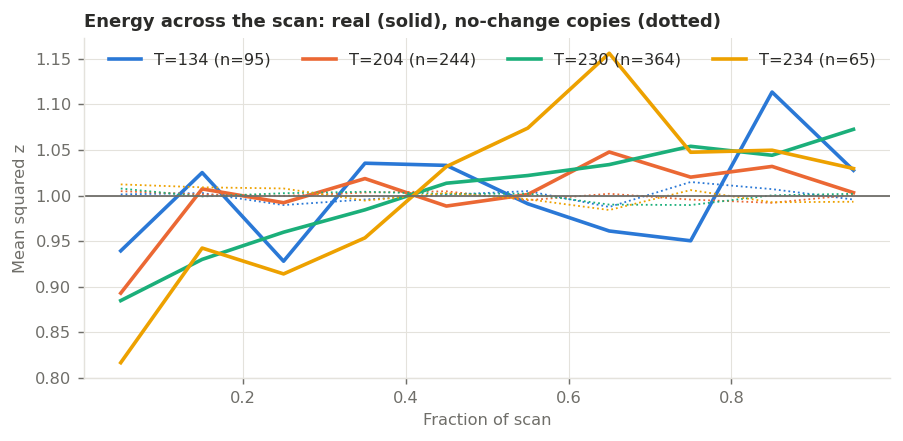

2026-10-30 23:52:27,526 DONE  variance_over_scan (5.4s)


In [6]:
ENERGY_NULL = []


def log_ratio(energy):
    return np.log(energy[:M].mean() / energy[M:].mean())


def boot_ci(values):
    values = np.asarray(values)
    picks = rng.integers(0, len(values), (N_BOOT, len(values)))
    return np.quantile(np.median(values[picks], axis=1), [.025, .975]).round(4).tolist()


@step
def variance_over_scan():
    generator = np.random.default_rng(SEED + 1)
    deciles, deciles_null = {}, {}
    ratios, ratios_null = {}, {}
    for sid, x in tqdm(TC.items(), desc="variance"):
        energy = frame_energy(x)
        T = len(x)
        surrogates = [frame_energy(phase_randomise(x, generator)) for _ in range(N_SURROGATES)]
        ENERGY_NULL.extend(pd.Series(e).rolling(5, center=True).mean().max() for e in surrogates)
        deciles.setdefault(T, []).append([c.mean() for c in np.array_split(energy, 10)])
        deciles_null.setdefault(T, []).append(np.mean([[c.mean() for c in np.array_split(e, 10)] for e in surrogates], axis=0))
        if T >= MIN_T_FOR_M:
            ratios.setdefault(T, []).append(log_ratio(energy))
            ratios_null.setdefault(T, []).extend(log_ratio(e) for e in surrogates)
    rows = []
    for T in sorted(ratios):
        rows.append({"T": T, "scans": len(ratios[T]), "median_log_ratio": np.median(ratios[T]),
                     "share_quieter": np.mean(np.array(ratios[T]) < 0),
                     "null_median": np.median(ratios_null[T]), "null_share_quieter": np.mean(np.array(ratios_null[T]) < 0)})
    pooled = np.concatenate([ratios[T] for T in ratios])
    pooled_null = np.concatenate([ratios_null[T] for T in ratios])
    table = pd.DataFrame(rows)
    table.to_csv(OUT / "training_block_variance.csv", index=False)
    print(table.round(4).to_string(index=False))
    SUMMARY["training_block_variance"] = {
        "median_log_ratio": float(np.median(pooled)), "ci95": boot_ci(pooled),
        "variance_ratio_at_median": float(np.exp(np.median(pooled))),
        "share_quieter": float(np.mean(pooled < 0)), "null_median": float(np.median(pooled_null)),
        "null_share_quieter": float(np.mean(pooled_null < 0)),
    }
    print(json.dumps(SUMMARY["training_block_variance"], indent=2))

    shown = [T for T in sorted(deciles) if len(deciles[T]) >= 50]
    fig, ax = plt.subplots(figsize=(8, 3.4))
    x_axis = (np.arange(10) + .5) / 10
    for T, color in zip(shown, LINE_COLORS):
        ax.plot(x_axis, np.mean(deciles[T], axis=0), color=color, label=f"T={T} (n={len(deciles[T])})")
        ax.plot(x_axis, np.mean(deciles_null[T], axis=0), color=color, lw=1, ls=":")
    ax.axhline(1, color=MUTED, lw=1)
    ax.set(title="Energy across the scan: real (solid), no-change copies (dotted)",
           xlabel="Fraction of scan", ylabel="Mean squared z")
    ax.legend(ncols=len(shown))
    save_fig(fig, "energy_over_scan")

## 5a. Artifact bursts

One example scan had a burst that pushed an edge from about 0.7 to 0.98, the
kind of event a detector would flag. A burst here is a 5-volume run of energy
above the 99th percentile of the same peak in no-change copies. Motion
regressors are not in the data, so this is the only available measure of them.

2026-10-30 23:52:27,567 START bursts
threshold 2.91
     scans  share_with_burst  median_burst_volumes
T                                                 
100      8             0.125                   0.0
134     95             0.432                   0.0
204    244             0.344                   0.0
208      1             1.000                   3.0
210      9             0.444                   0.0
230    364             0.434                   0.0
234     65             0.446                   0.0
{
  "threshold": 2.914354969640747,
  "share_scans_with_burst": 0.40458015267175573,
  "share_scans_over_5pct_of_volumes": 0.06997455470737914,
  "share_of_all_volumes": 0.012961407864471138
}


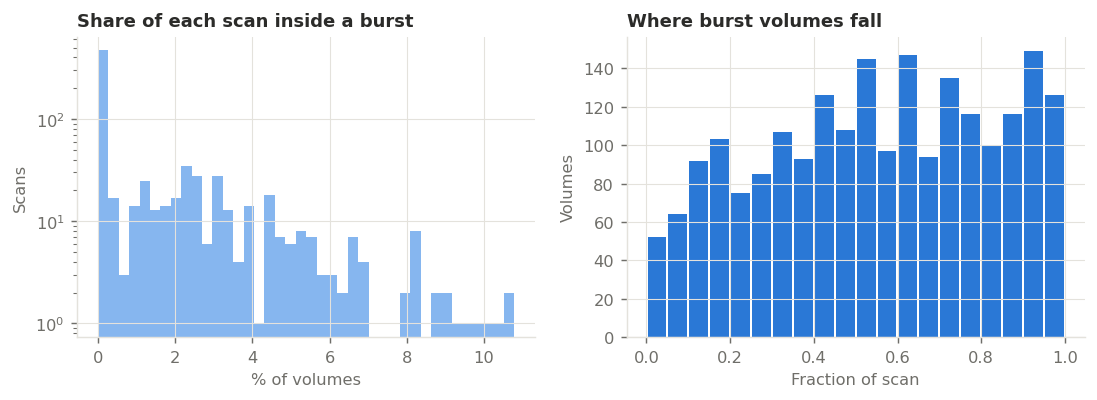

2026-10-30 23:52:28,869 DONE  bursts (1.3s)


In [7]:
@step
def bursts():
    threshold = float(np.quantile(ENERGY_NULL, .99))
    rows = []
    position = np.zeros(20)
    for sid, x in TC.items():
        smooth = pd.Series(frame_energy(x)).rolling(5, center=True).mean().to_numpy()
        flagged = np.flatnonzero(smooth > threshold)
        rows.append({"scan": sid, "T": len(x), "peak": np.nanmax(smooth), "burst_volumes": len(flagged),
                     "share_of_scan": len(flagged) / len(x)})
        if len(flagged):
            np.add.at(position, (flagged * 20 / len(x)).astype(int), 1)
    table = pd.DataFrame(rows)
    table.to_csv(OUT / "bursts.csv", index=False)
    by_length = table.groupby("T").agg(scans=("scan", "size"), share_with_burst=("burst_volumes", lambda v: (v > 0).mean()),
                                       median_burst_volumes=("burst_volumes", "median")).round(3)
    print(f"threshold {threshold:.2f}\n", by_length.to_string(), sep="")
    SUMMARY["bursts"] = {
        "threshold": threshold, "share_scans_with_burst": float((table["burst_volumes"] > 0).mean()),
        "share_scans_over_5pct_of_volumes": float((table["share_of_scan"] > .05).mean()),
        "share_of_all_volumes": float(table["burst_volumes"].sum() / table["T"].sum()),
    }
    print(json.dumps(SUMMARY["bursts"], indent=2))

    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    axes[0].hist(table["share_of_scan"] * 100, bins=40, color="#86b6ef")
    axes[0].set(title="Share of each scan inside a burst", xlabel="% of volumes", ylabel="Scans", yscale="log")
    axes[1].bar((np.arange(20) + .5) / 20, position, width=.045, color=BLUE)
    axes[1].set(title="Where burst volumes fall", xlabel="Fraction of scan", ylabel="Volumes")
    save_fig(fig, "bursts")

## 5b. Redundant ICNs and a working order

The file order is not sorted by domain, and the template is multi-scale, so
some ICNs may be near-copies. Those inflate the nominal 105 dimensions and
make partial correlations unstable. Clustering gives a working order until the
domain labels come from the template itself.

2026-10-30 23:52:28,911 START icn_structure
Most correlated ICN pairs:
 icn_a  icn_b  mean_r
    13     90   0.938
     4     57   0.914
    44     58   0.912
    44     63   0.894
    34     49   0.893
    50     84   0.893
    24     60   0.888
    32     88   0.877
    38     84   0.876
    65     69   0.864
    65     87   0.856
     2     83   0.844
    36     57   0.843
    12     46   0.838
    18     99   0.829
mean r > 0.5: 15 groups, largest [24, 22, 15, 11, 11, 6], pairs 228
mean r > 0.6: 29 groups, largest [15, 11, 10, 10, 9, 6], pairs 137
mean r > 0.7: 45 groups, largest [10, 6, 6, 5, 5, 4], pairs 75
mean r > 0.8: 80 groups, largest [4, 3, 3, 3, 3, 3], pairs 27
cluster_k6 sizes [25, 22, 20, 18, 11, 9]
cluster_k7 sizes [25, 22, 20, 18, 11, 5, 4]
cluster_k10 sizes [20, 16, 14, 13, 12, 11, 8, 5, 4, 2]


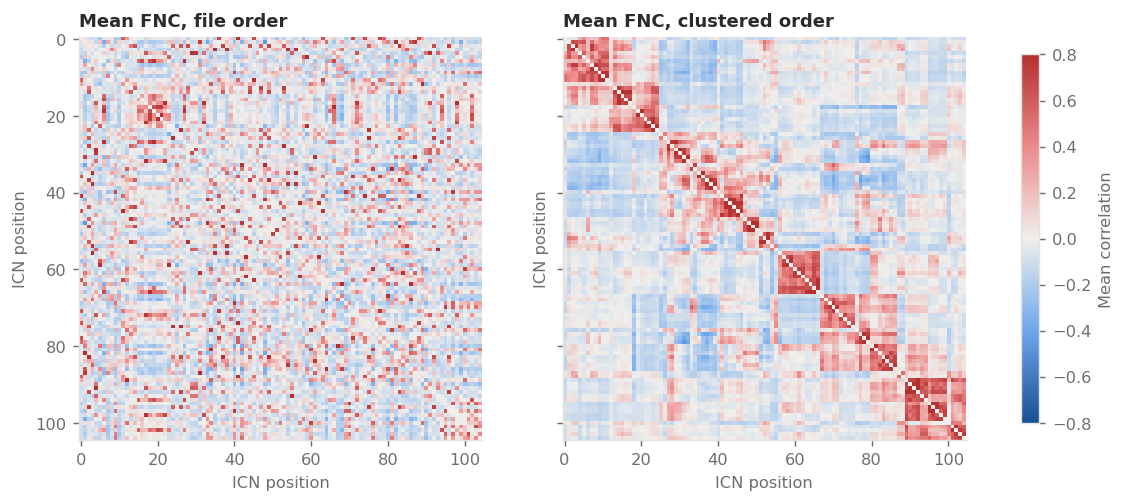

2026-10-30 23:52:29,738 DONE  icn_structure (0.8s)


In [8]:
@step
def icn_structure():
    z = np.mean([np.arctanh(np.clip(FNC[s], -.999999, .999999)) for s in FNC], axis=0)
    mean_r = square(np.tanh(z))
    np.save(OUT / "mean_fnc_r.npy", mean_r)
    off = mean_r.copy()
    np.fill_diagonal(off, 0)
    top = np.argsort(-off[UPPER])[:15]
    pairs = pd.DataFrame({"icn_a": UPPER[0][top] + 1, "icn_b": UPPER[1][top] + 1, "mean_r": off[UPPER][top]})
    print("Most correlated ICN pairs:\n", pairs.round(3).to_string(index=False), sep="")
    for cutoff in (.5, .6, .7, .8):
        n, labels = connected_components(off > cutoff, directed=False)
        sizes = np.sort(np.bincount(labels))[::-1]
        print(f"mean r > {cutoff}: {n} groups, largest {sizes[:6].tolist()}, pairs {int((off[UPPER] > cutoff).sum())}")
    distance = 1 - mean_r[UPPER]
    linkage = sch.linkage(distance, method="average")
    order = sch.leaves_list(linkage)
    clusters = {f"cluster_k{k}": sch.fcluster(linkage, k, "maxclust") for k in (6, 7, 10)}
    pd.DataFrame({"icn": np.arange(1, P + 1), **clusters, "plot_position": np.argsort(order) + 1}).to_csv(
        OUT / "icn_working_clusters.csv", index=False)
    for name, labels in clusters.items():
        print(name, "sizes", np.sort(np.bincount(labels)[1:])[::-1].tolist())
    SUMMARY["icn_pairs_above_0.7"] = int((off[UPPER] > .7).sum())

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
    for ax, matrix, title in ((axes[0], off, "Mean FNC, file order"),
                              (axes[1], off[np.ix_(order, order)], "Mean FNC, clustered order")):
        image = ax.imshow(matrix, cmap=DIV_FNC, vmin=-.8, vmax=.8, interpolation="nearest")
        ax.set(title=title, xlabel="ICN position", ylabel="ICN position")
        ax.grid(False)
    fig.colorbar(image, ax=axes, shrink=.8, label="Mean correlation")
    save_fig(fig, "mean_fnc_clustered")

In [9]:
def as_json(value):
    if isinstance(value, (np.integer, np.bool_)):
        return value.item()
    if isinstance(value, np.floating):
        return float(value)
    return str(value)


@step
def package():
    (OUT / "summary.json").write_text(json.dumps(SUMMARY, indent=2, default=as_json))
    archive = shutil.make_archive(str(WORK_ROOT / "01b-followup-results"), "zip", OUT)
    log.info("wrote %s", archive)
    log.info("sections failed: %s", SUMMARY["sections_failed"] or "none")

2026-10-30 23:52:29,764 START package
2026-10-30 23:52:29,791 wrote /kaggle/working/01b-followup-results.zip
2026-10-30 23:52:29,792 sections failed: none
2026-10-30 23:52:29,793 DONE  package (0.0s)
